# Experiment 9: Generation of Synthetic Images Using a GAN


## Aim
To implement and train a Generative Adversarial Network (GAN) to generate synthetic images using adversarial learning.

Dinesh Kumar P - 24BAD021

## Part A: Dataset preparation

Experiment 8: GAN
Student Name: Dhanya G
Register Number: 24BAD019
TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)
Original pixel range: 0 to 255
Normalized training shape: (60000, 28, 28, 1)
Normalized pixel range: -1.0 to 1.0


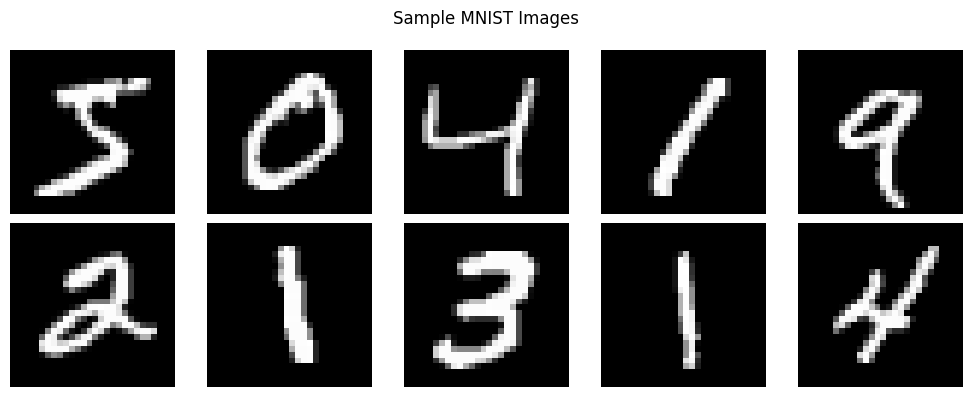

Dinesh Kumar P - 24BAD021


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, Model

print("Experiment 8: GAN")
print("Student Name: Dhanya G")
print("Register Number: 24BAD019")
print("TensorFlow version:", tf.__version__)

(x_train, _), (x_test, _) = mnist.load_data()
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)
print("Original pixel range:", x_train.min(), "to", x_train.max())

x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)
x_test = (x_test.astype("float32") - 127.5) / 127.5
x_test = np.expand_dims(x_test, axis=-1)

print("Normalized training shape:", x_train.shape)
print("Normalized pixel range:", x_train.min(), "to", x_train.max())

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

batch_size = 128
dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(60000).batch(batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
print("Dinesh Kumar P - 24BAD021")

## Part B: Implementing the Generator and Discriminator

In [2]:
latent_dim = 100

generator = tf.keras.Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(7 * 7 * 128, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Reshape((7, 7, 128)),
    layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")
], name="Generator")

discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 4, strides=2, padding="same"),
    layers.LeakyReLU(),
    layers.Dropout(0.3),
    layers.Conv2D(128, 4, strides=2, padding="same"),
    layers.LeakyReLU(),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1)
], name="Discriminator")

generator.summary()
discriminator.summary()
print("Dinesh Kumar P - 24BAD021")

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

Dinesh Kumar P - 24BAD021


## Part C: GAN training and performance monitoring

Epoch 1/10 - Generator Loss: 0.8499 - Discriminator Loss: 1.0356


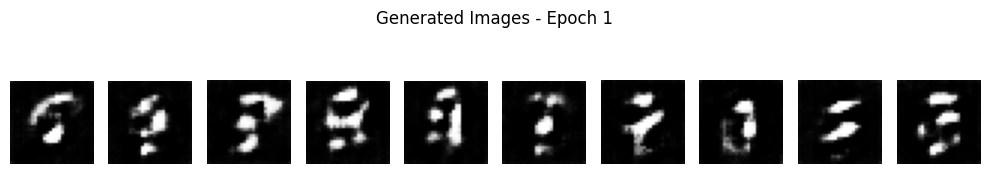

Epoch 2/10 - Generator Loss: 0.8007 - Discriminator Loss: 1.2797


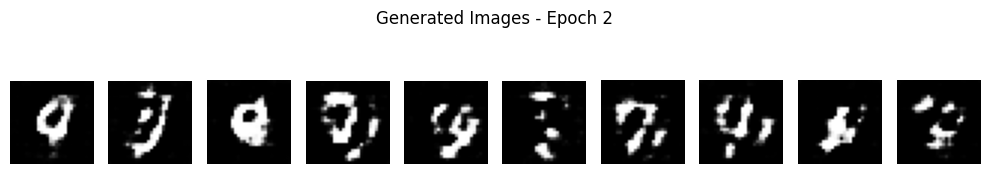

Epoch 3/10 - Generator Loss: 0.7919 - Discriminator Loss: 1.2990
Epoch 4/10 - Generator Loss: 0.8216 - Discriminator Loss: 1.2599


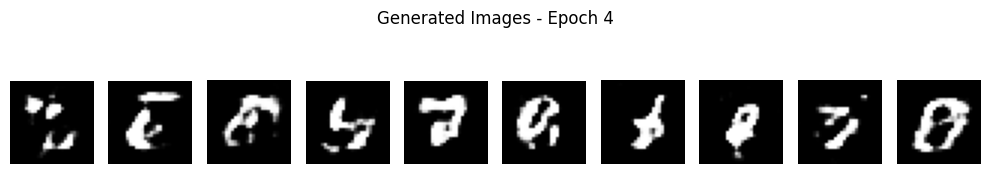

Epoch 5/10 - Generator Loss: 0.8782 - Discriminator Loss: 1.2037
Epoch 6/10 - Generator Loss: 0.9119 - Discriminator Loss: 1.1774


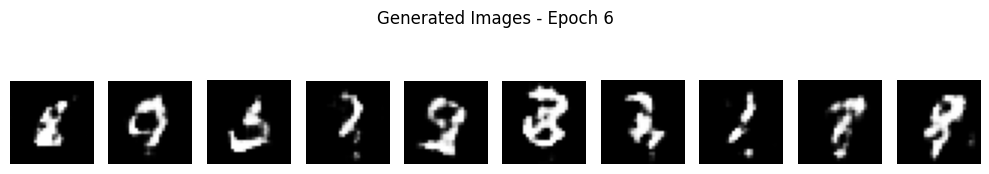

Epoch 7/10 - Generator Loss: 0.9169 - Discriminator Loss: 1.1869
Epoch 8/10 - Generator Loss: 0.9132 - Discriminator Loss: 1.2073


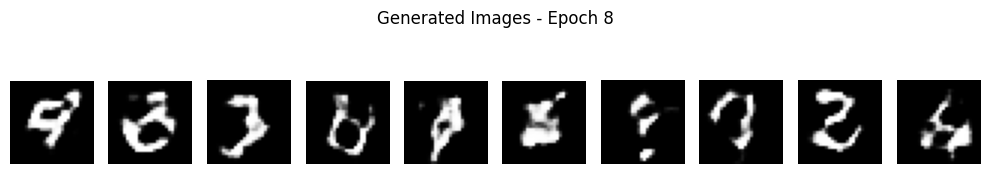

Epoch 9/10 - Generator Loss: 0.8959 - Discriminator Loss: 1.2319
Epoch 10/10 - Generator Loss: 0.8811 - Discriminator Loss: 1.2464


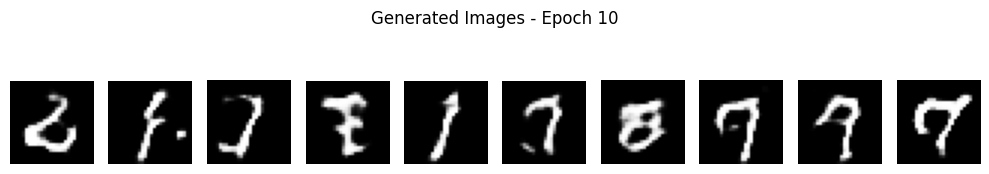

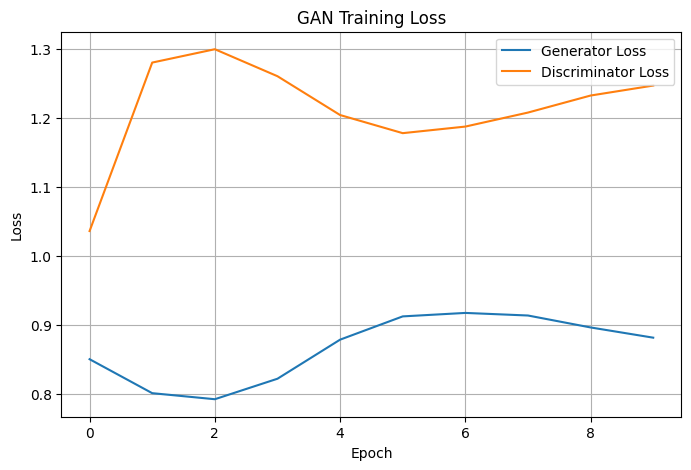

Dinesh Kumar P - 24BAD021


In [3]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
generator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)

@tf.function
def train_step(real_images):
    noise = tf.random.normal([batch_size, latent_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = cross_entropy(tf.ones_like(fake_output), fake_output)
        real_loss = cross_entropy(tf.ones_like(real_output), real_output)
        fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
        disc_loss = real_loss + fake_loss

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

def show_generated_images(epoch, count=10):
    noise = tf.random.normal([count, latent_dim])
    predictions = generator(noise, training=False)
    predictions = (predictions + 1) / 2

    plt.figure(figsize=(10, 2))
    for i in range(count):
        plt.subplot(1, count, i + 1)
        plt.imshow(predictions[i, :, :, 0], cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.tight_layout()
    plt.show()

epochs = 10
generator_losses = []
discriminator_losses = []

for epoch in range(1, epochs + 1):
    gen_epoch_losses = []
    disc_epoch_losses = []

    for image_batch in dataset:
        gen_loss, disc_loss = train_step(image_batch)
        gen_epoch_losses.append(float(gen_loss))
        disc_epoch_losses.append(float(disc_loss))

    generator_losses.append(np.mean(gen_epoch_losses))
    discriminator_losses.append(np.mean(disc_epoch_losses))

    print(
        f"Epoch {epoch}/{epochs} - "
        f"Generator Loss: {generator_losses[-1]:.4f} - "
        f"Discriminator Loss: {discriminator_losses[-1]:.4f}"
    )

    if epoch == 1 or epoch % 2 == 0:
        show_generated_images(epoch)

plt.figure(figsize=(8, 5))
plt.plot(generator_losses, label="Generator Loss")
plt.plot(discriminator_losses, label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()
print("Dinesh Kumar P - 24BAD021")

## Part D: Generate and compare synthetic images

The supplied Part D mentions movie-review sentences and an LSTM Encoder, which do not match this GAN experiment. This section follows the GAN objective and generates synthetic images.

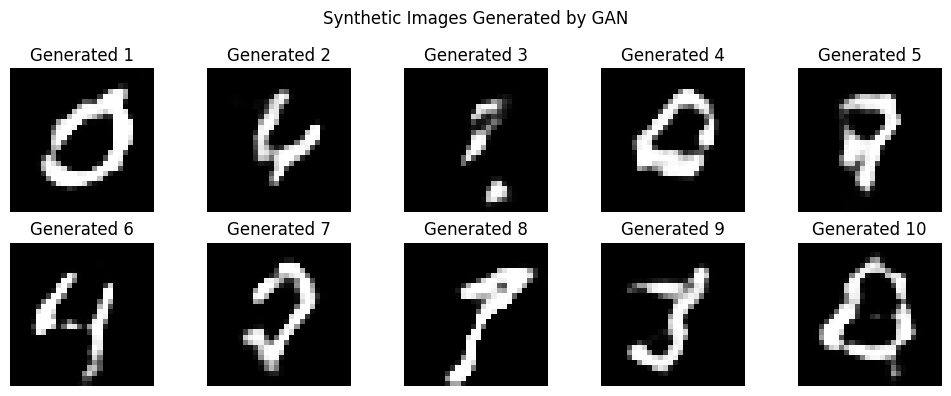

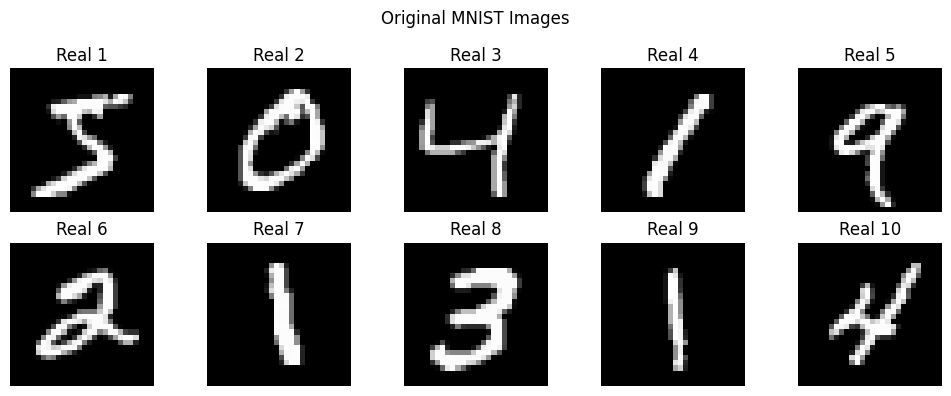

GAN experiment completed.
Generated image shape: (10, 28, 28, 1)
Generator loss at final epoch: 0.8811
Discriminator loss at final epoch: 1.2464
Dinesh Kumar P - 24BAD021


In [4]:
noise = tf.random.normal([10, latent_dim])
synthetic_images = generator(noise, training=False)
synthetic_images = (synthetic_images + 1) / 2

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(synthetic_images[i, :, :, 0], cmap="gray")
    plt.title(f"Generated {i + 1}")
    plt.axis("off")
plt.suptitle("Synthetic Images Generated by GAN")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow((x_train[i, :, :, 0] + 1) / 2, cmap="gray")
    plt.title(f"Real {i + 1}")
    plt.axis("off")
plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()

print("GAN experiment completed.")
print("Generated image shape:", synthetic_images.shape)
print("Generator loss at final epoch:", round(generator_losses[-1], 4))
print("Discriminator loss at final epoch:", round(discriminator_losses[-1], 4))
print("Dinesh Kumar P - 24BAD021")